# 06 — Deduplicating Training Data & Expanding Zeek Features

Two focused questions before we lock in a final candidate and run the official test set **once**:

1. **Does removing duplicate rows from training help?**
   Our leak-free split already keeps duplicates from crossing into validation, but the training split (`X_fit`) still contains ~39% exact duplicates. Training on duplicates gives repeated patterns extra weight—does removing them improve validation FPR?
2. **Can we close the Zeek feature gap without non-Zeek columns?**
   In notebook 05, the 9 basic `zeek_core` features doubled validation false alarms (`4.3% → 8.0%`). Here we test two realistic steps up that Zeek `conn.log` *can* compute:
   - **`zeek_flow` (14 features):** `zeek_core` + 5 single-row values (`rate`, `smean`, `dmean`, `state`, `is_sm_ips_ports`).
   - **`zeek_windowed` (21 features):** `zeek_flow` + 7 connection-count features computed over a sliding window of the last 100 flows (`ct_srv_src`, `ct_dst_ltm`, `ct_src_dport_ltm`, `ct_dst_sport_ltm`, `ct_dst_src_ltm`, `ct_src_ltm`, `ct_srv_dst`).

**Evaluation setup:** same leak-free `validation_split` (80/20) and threshold rule (recall ≥ 95%, lowest FPR). Validation only; the official test set stays untouched.

## 1. Setup & helper function

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.pipeline import Pipeline

from cybershield.ml.preprocessing import (
    CATEGORICAL,
    TRAIN_CSV,
    build_preprocessor,
    load_csv,
    split_xy,
    validation_split,
)
from cybershield.ml.train import FINALISTS, evaluate

MIN_RECALL = 0.95

X, y = split_xy(load_csv(TRAIN_CSV))
X_fit, X_val, y_fit, y_val = validation_split(X, y)

# Deduplicate X_fit only (keep X_val untouched so every experiment is judged on the same rows)
keep_mask = ~X_fit.duplicated(keep="first")
X_fit_dedup = X_fit.loc[keep_mask]
y_fit_dedup = y_fit.loc[keep_mask]

print(f"X_fit original:     {len(X_fit):,} rows")
print(f"X_fit deduplicated: {len(X_fit_dedup):,} rows ({1 - len(X_fit_dedup) / len(X_fit):.1%} removed)")
print(f"X_val (fixed):      {len(X_val):,} rows")


def choose_threshold(y_true, proba, min_recall=MIN_RECALL):
    """Highest threshold (0.99 down to 0.01) keeping recall >= min_recall."""
    y_true = np.asarray(y_true)
    attacks = y_true == 1
    for t in np.round(np.arange(0.99, 0.00, -0.01), 2):
        if (proba[attacks] >= t).mean() >= min_recall:
            return float(t)
    return 0.01


def run_experiment(label, cols, X_tr, y_tr):
    categorical = [c for c in CATEGORICAL if c in cols]
    out = []
    for model_name, make in FINALISTS.items():
        model = Pipeline(
            [
                ("preprocess", build_preprocessor(categorical=categorical)),
                ("classifier", make()),
            ]
        )
        model.fit(X_tr[cols], y_tr)
        proba = model.predict_proba(X_val[cols])[:, 1]
        t = choose_threshold(y_val, proba)
        m = evaluate(y_val, (proba >= t).astype(int))
        out.append(
            {
                "experiment": label,
                "n_features": len(cols),
                "model": model_name,
                "threshold": t,
                "val_recall": m["recall"],
                "val_fpr": m["false_positive_rate"],
                "val_f1": m["f1"],
                "false_alarms": m["confusion_matrix"]["fp"],
                "missed_attacks": m["confusion_matrix"]["fn"],
            }
        )
    return out

X_fit original:     140,274 rows
X_fit deduplicated: 80,821 rows (42.4% removed)
X_val (fixed):      35,067 rows


## 2. Experiment A — Original vs. deduplicated training data
Both models train on all 42 features, once with `X_fit` as-is and once with exact duplicates removed. Both are evaluated on the exact same `X_val`.

In [2]:
all_cols = list(X.columns)
dedup_rows = (
    run_experiment("original_fit", all_cols, X_fit, y_fit)
    + run_experiment("dedup_fit", all_cols, X_fit_dedup, y_fit_dedup)
)
dedup_df = pd.DataFrame(dedup_rows).round(4)
dedup_df

,experiment,n_features,model,threshold,val_recall,val_fpr,val_f1,false_alarms,missed_attacks
0,original_fit,42,rf-baseline-v1,0.65,0.9514,0.0485,0.9639,543,1160
1,original_fit,42,hgb-v1,0.69,0.9504,0.0429,0.9646,480,1184
2,dedup_fit,42,rf-baseline-v1,0.63,0.9511,0.0518,0.9629,580,1168
3,dedup_fit,42,hgb-v1,0.65,0.9506,0.0504,0.9630,565,1178


## 3. Experiment B — Expanding Zeek-computable features
Compare the four feature sets on the same `X_fit` / `X_val` split:
- `zeek_core` (9) → `zeek_flow` (14) → `zeek_windowed` (21) → `all` (42)

In [3]:
ZEEK_CORE = ["dur", "proto", "service", "spkts", "dpkts", "sbytes", "dbytes", "sload", "dload"]
ZEEK_FLOW = ZEEK_CORE + ["rate", "smean", "dmean", "state", "is_sm_ips_ports"]
ZEEK_WINDOWED = ZEEK_FLOW + [
    "ct_srv_src",
    "ct_dst_ltm",
    "ct_src_dport_ltm",
    "ct_dst_sport_ltm",
    "ct_dst_src_ltm",
    "ct_src_ltm",
    "ct_srv_dst",
]

FEATURE_SETS = {
    "zeek_core": ZEEK_CORE,
    "zeek_flow": ZEEK_FLOW,
    "zeek_windowed": ZEEK_WINDOWED,
    "all": all_cols,
}

zeek_rows = []
for name, cols in FEATURE_SETS.items():
    zeek_rows.extend(run_experiment(name, cols, X_fit, y_fit))

zeek_df = pd.DataFrame(zeek_rows).round(4)
zeek_df

,experiment,n_features,model,threshold,val_recall,val_fpr,val_f1,false_alarms,missed_attacks
0,zeek_core,9,rf-baseline-v1,0.61,0.9501,0.0869,0.9544,973,1192
1,zeek_core,9,hgb-v1,0.59,0.9528,0.0804,0.9573,901,1127
2,zeek_flow,14,rf-baseline-v1,0.61,0.9501,0.0854,0.9548,957,1192
3,zeek_flow,14,hgb-v1,0.60,0.9507,0.0768,0.9570,860,1177
4,zeek_windowed,21,rf-baseline-v1,0.66,0.9510,0.0504,0.9632,565,1170
5,zeek_windowed,21,hgb-v1,0.68,0.9501,0.0454,0.9639,508,1192
6,all,42,rf-baseline-v1,0.65,0.9514,0.0485,0.9639,543,1160
7,all,42,hgb-v1,0.69,0.9504,0.0429,0.9646,480,1184


## 4. Visual comparison — Zeek feature progression

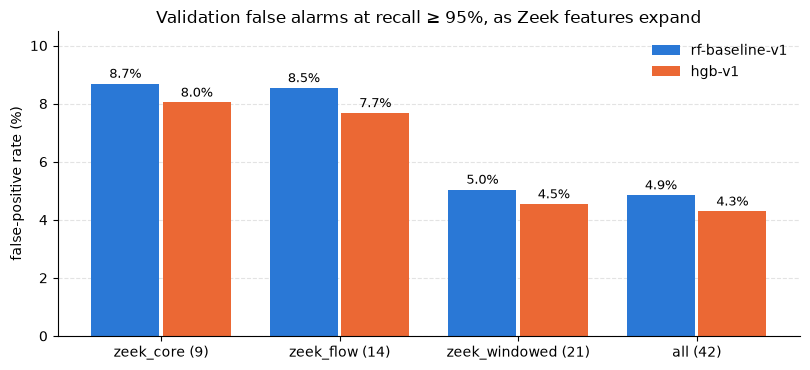

In [4]:
fig, ax = plt.subplots(figsize=(8.2, 3.8))
set_order = list(FEATURE_SETS)
x = np.arange(len(set_order))

for offset, (model_name, color) in zip((-0.2, 0.2), [("rf-baseline-v1", "#2a78d6"), ("hgb-v1", "#eb6834")]):
    subset = zeek_df[zeek_df["model"] == model_name].set_index("experiment").loc[set_order]
    rates = subset["val_fpr"] * 100
    ax.bar(x + offset, rates, width=0.38, color=color, label=model_name)
    for i, rate in enumerate(rates):
        ax.text(i + offset, rate + 0.2, f"{rate:.1f}%", ha="center", fontsize=9)

ax.set(
    xticks=x,
    xticklabels=[f"{k} ({len(FEATURE_SETS[k])})" for k in set_order],
    ylabel="false-positive rate (%)",
    ylim=(0, zeek_df["val_fpr"].max() * 100 + 1.8),
    title="Validation false alarms at recall ≥ 95%, as Zeek features expand",
)
ax.grid(axis="y", linestyle="--", alpha=0.35)
ax.set_axisbelow(True)
ax.legend(frameon=False)
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

## Key takeaways
- **Don't deduplicate the training set (`X_fit`):** removing 42.4% of rows hurt validation FPR for both models (`hgb-v1`: **4.3% → 5.0%**, +85 false alarms; `rf-baseline-v1`: **4.9% → 5.2%**, +37 false alarms). Keeping duplicates inside `X_fit` preserves real traffic frequencies—as long as `validation_split` keeps copies from crossing into validation.
- **Single-flow Zeek math (`zeek_flow`, 14 features) only helps a little:** adding `rate`, `smean`, `dmean`, `state`, and `is_sm_ips_ports` nudges `hgb-v1` FPR from **8.0% → 7.7%** (901 → 860 false alarms).
- **Sliding-window counts (`zeek_windowed`, 21 features) close almost the entire gap:** adding the 7 connection-count features over the last 100 flows drops `hgb-v1` FPR from **7.7% → 4.5%** (508 false alarms)—just **0.25 percentage points** behind using all 42 UNSW features (**4.3%**, 480 false alarms), with **no TTL or TCP-internals needed**.
- **Clear finalist candidate:** `hgb-v1` trained on **`zeek_windowed` (21 features)** with the original (non-deduplicated) training split and threshold **`0.68`** (at recall ≥ 95%).
